In [3]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [4]:
import pandas as pd

df = pd.read_csv("ai4i2020.csv")

In [5]:
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [6]:
df.shape

(10000, 14)

In [7]:
df.isnull().sum()

UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

In [8]:
df.describe()

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


array([[<Axes: title={'center': 'UDI'}>,
        <Axes: title={'center': 'Air temperature [K]'}>,
        <Axes: title={'center': 'Process temperature [K]'}>],
       [<Axes: title={'center': 'Rotational speed [rpm]'}>,
        <Axes: title={'center': 'Torque [Nm]'}>,
        <Axes: title={'center': 'Tool wear [min]'}>],
       [<Axes: title={'center': 'Machine failure'}>,
        <Axes: title={'center': 'TWF'}>, <Axes: title={'center': 'HDF'}>],
       [<Axes: title={'center': 'PWF'}>, <Axes: title={'center': 'OSF'}>,
        <Axes: title={'center': 'RNF'}>]], dtype=object)

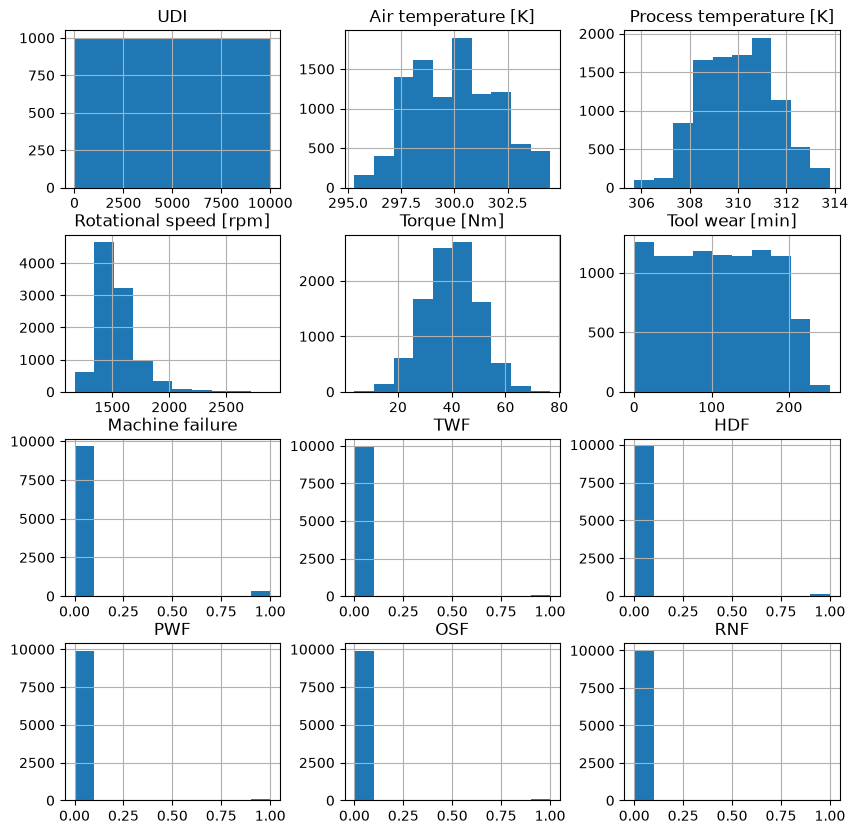

In [9]:
df.hist(figsize=(10,10))

In [10]:
df["Machine failure"].unique()

array([0, 1])

In [11]:
df["Machine failure"].value_counts()

Machine failure
0    9661
1     339
Name: count, dtype: int64

<Axes: xlabel='Machine failure', ylabel='count'>

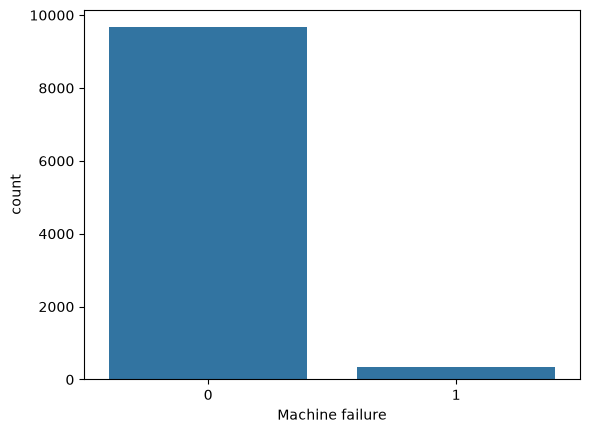

In [12]:
sns.countplot(x="Machine failure", data=df)

In [13]:
df.columns

Index(['UDI', 'Product ID', 'Type', 'Air temperature [K]',
       'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]',
       'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF',
       'RNF'],
      dtype='str')

In [14]:
df.columns = df.columns.str.strip()

failure_cols = ['TWF', 'HDF', 'PWF', 'OSF', 'RNF']

def classify_failure_type(row):
    for col in failure_cols:
        if row[col] == 1:
            return col
    return "No failure"

In [15]:
df["Failure Type"] = df.apply(classify_failure_type, axis=1)

In [16]:
df["Failure Type"]

0       No failure
1       No failure
2       No failure
3       No failure
4       No failure
           ...    
9995    No failure
9996    No failure
9997    No failure
9998    No failure
9999    No failure
Name: Failure Type, Length: 10000, dtype: str

<Axes: xlabel='Failure Type', ylabel='count'>

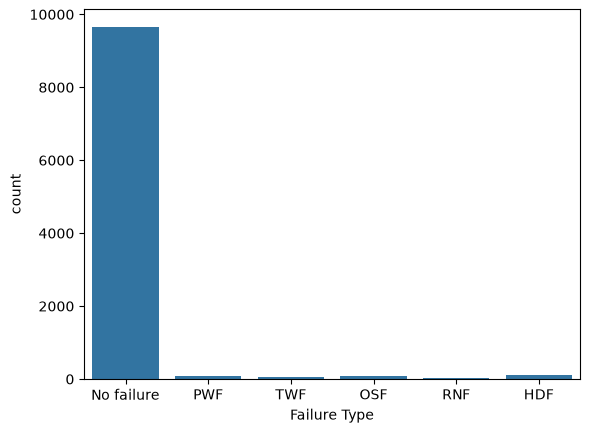

In [17]:
sns.countplot(x="Failure Type", data=df)

<Axes: xlabel='Type', ylabel='count'>

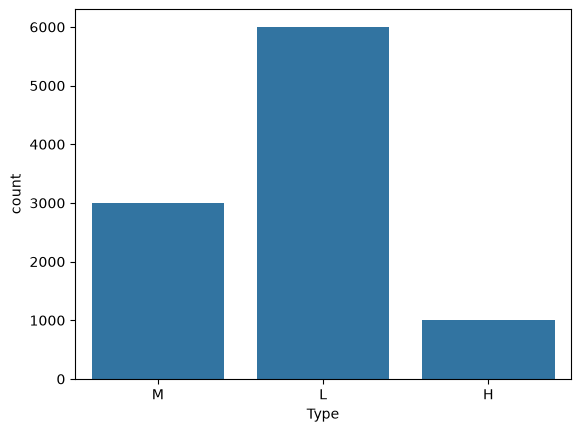

In [18]:
sns.countplot(x="Type", data=df)

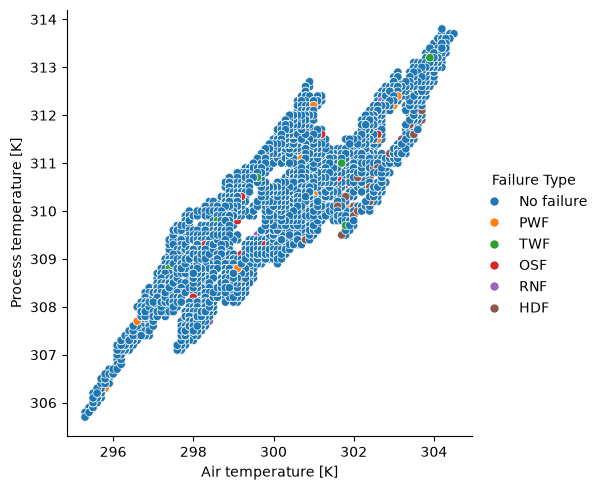

In [19]:
sns.relplot(x="Air temperature [K]", y="Process temperature [K]", hue="Failure Type",sizes=(100,5),data=df)

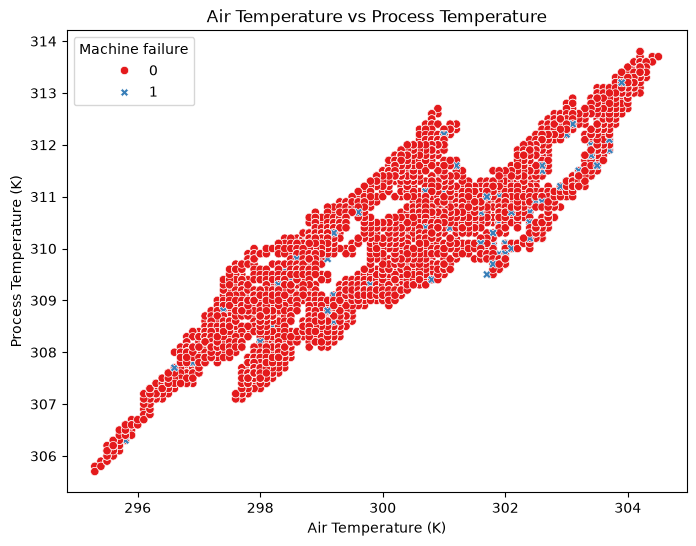

In [20]:

plt.figure(figsize=(8,6))

sns.scatterplot(
    x='Air temperature [K]',
    y='Process temperature [K]',
    hue='Machine failure',
    style='Machine failure',
    palette='Set1',
    data=df
)

plt.title('Air Temperature vs Process Temperature')
plt.xlabel('Air Temperature (K)')
plt.ylabel('Process Temperature (K)')
plt.show()


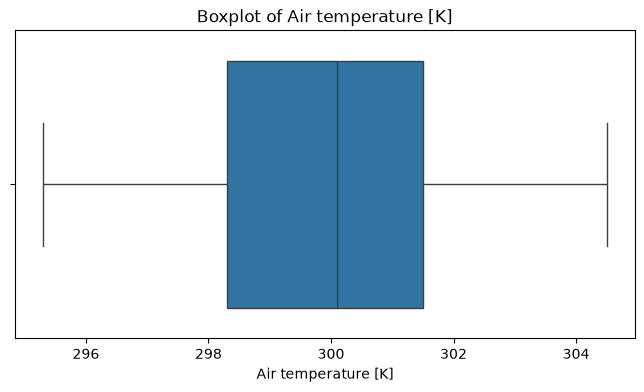

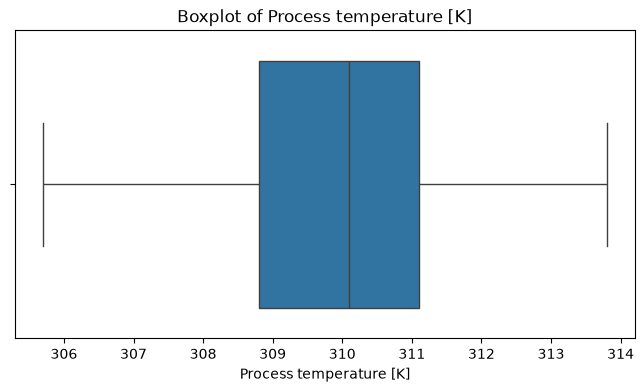

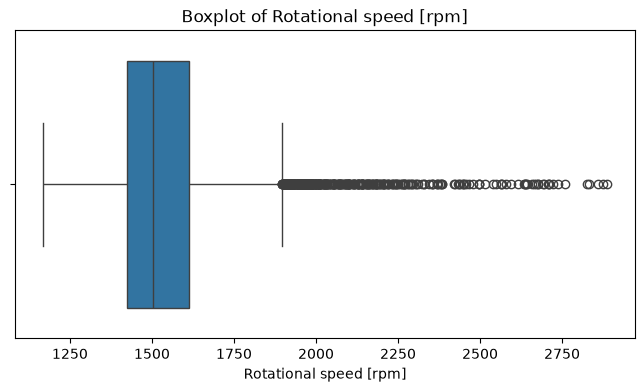

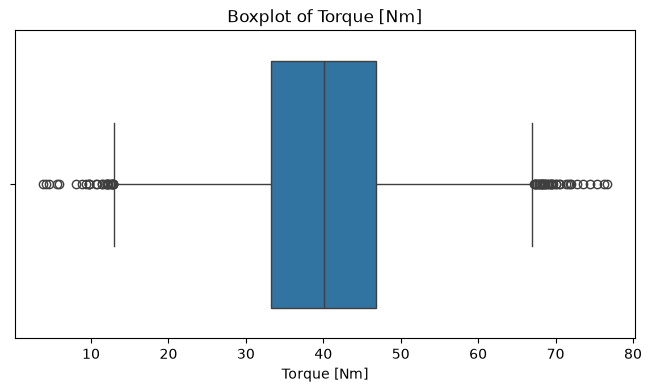

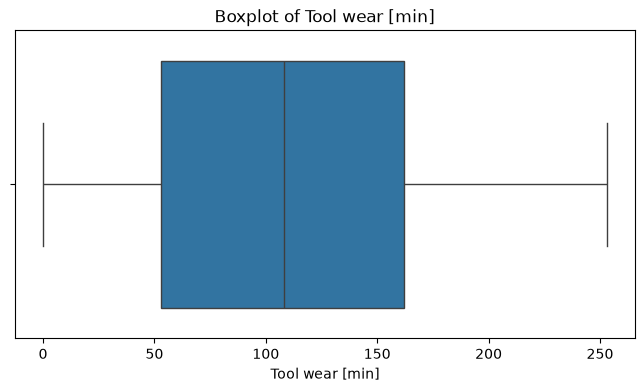

In [21]:
sensor_cols = [
    'Air temperature [K]',
    'Process temperature [K]',
    'Rotational speed [rpm]',
    'Torque [Nm]',
    'Tool wear [min]'
]

for col in sensor_cols:
    plt.figure(figsize=(8, 4))
    sns.boxplot(x=df[col])
    plt.title(f'Boxplot of {col}')
    plt.xlabel(col)
    plt.show()


Featuring Engineering

In [22]:
df.columns

Index(['UDI', 'Product ID', 'Type', 'Air temperature [K]',
       'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]',
       'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF',
       'Failure Type'],
      dtype='str')

In [23]:
df["Type"].unique()

<StringArray>
['M', 'L', 'H']
Length: 3, dtype: str

In [24]:
df['Type'] = df['Type'].map({'L': 0, 'M': 1, 'H': 2})

In [25]:
feature_cols = [
    'Type',
    'Air temperature [K]',
    'Process temperature [K]',
    'Rotational speed [rpm]',
    'Torque [Nm]',
    'Tool wear [min]'
]

X_features = df[feature_cols]
y_labels = df['Machine failure']

In [26]:
print(X_features.head())
print(y_labels.head())

   Type  Air temperature [K]  Process temperature [K]  Rotational speed [rpm]  \
0     1                298.1                    308.6                    1551   
1     0                298.2                    308.7                    1408   
2     0                298.1                    308.5                    1498   
3     0                298.2                    308.6                    1433   
4     0                298.2                    308.7                    1408   

   Torque [Nm]  Tool wear [min]  
0         42.8                0  
1         46.3                3  
2         49.4                5  
3         39.5                7  
4         40.0                9  
0    0
1    0
2    0
3    0
4    0
Name: Machine failure, dtype: int64


In [27]:
# Import ML libraries

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [29]:
# Split dataset

X_train, X_test, y_train, y_test = train_test_split(
    X_features,
    y_labels,
    test_size=0.25,
    random_state=42,
    stratify=y_labels
)

In [30]:
# Build Model

def build_model(classifier, x_train, y_train):
    classifier.fit(x_train, y_train)
    return classifier

In [31]:
# Random Forest

rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_clf = build_model(rf, X_train, y_train)

In [32]:
# Accuracy

rf_clf.score(X_test, y_test)

0.984

In [33]:
# Classification Report

y_pred = rf_clf.predict(X_test)

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.99      1.00      0.99      2415
           1       0.89      0.60      0.72        85

    accuracy                           0.98      2500
   macro avg       0.94      0.80      0.86      2500
weighted avg       0.98      0.98      0.98      2500



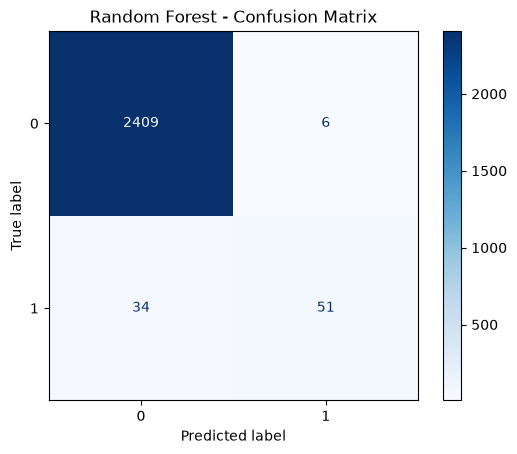

In [34]:
# Confusion Matrix

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm)

disp.plot(cmap='Blues')
plt.title('Random Forest - Confusion Matrix')
plt.show()

In [35]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression

In [36]:

# Logistic Regression

lr = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

lr_clf = lr.fit(X_train, y_train)

# Predictions
y_pred_lr = lr_clf.predict(X_test)

# Accuracy
print("Accuracy:", lr_clf.score(X_test, y_test))


Accuracy: 0.9676


In [37]:
print(classification_report(y_test, y_pred_lr))

              precision    recall  f1-score   support

           0       0.97      1.00      0.98      2415
           1       0.60      0.14      0.23        85

    accuracy                           0.97      2500
   macro avg       0.79      0.57      0.61      2500
weighted avg       0.96      0.97      0.96      2500



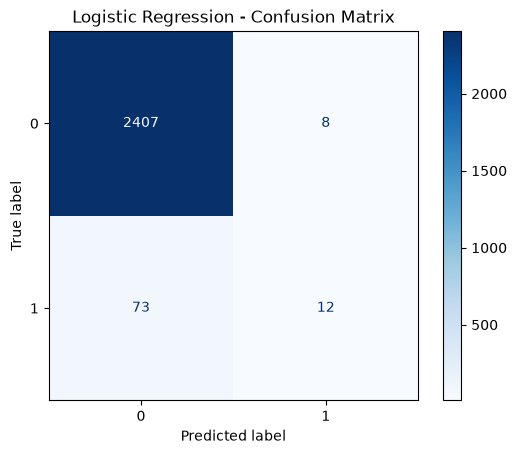

In [38]:
cm = confusion_matrix(y_test, y_pred_lr)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=lr_clf.classes_
)

disp.plot(cmap='Blues')
plt.title('Logistic Regression - Confusion Matrix')
plt.show()

In [39]:

# Sample Prediction

sample_data = X_test.iloc[[0]]

print("Actual Result:", y_test.iloc[0])

print("Logistic Regression Prediction:",
      lr_clf.predict(sample_data))

print("Random Forest Prediction:",
      rf_clf.predict(sample_data))


Actual Result: 0
Logistic Regression Prediction: [0]
Random Forest Prediction: [0]


In [40]:
# Extract Logistic Regression model

lr_model = lr_clf.named_steps['logisticregression']

In [41]:

import pandas as pd

# Feature weights

lr_importance = pd.DataFrame({
    'Feature': X_features.columns,
    'Weight': lr_model.coef_[0]
})

lr_importance = lr_importance.sort_values(
    by='Weight',
    key=abs,
    ascending=False
)

print(lr_importance)


                   Feature    Weight
4              Torque [Nm]  2.779963
3   Rotational speed [rpm]  2.059606
1      Air temperature [K]  1.460668
2  Process temperature [K] -0.997754
5          Tool wear [min]  0.826345
0                     Type -0.269462


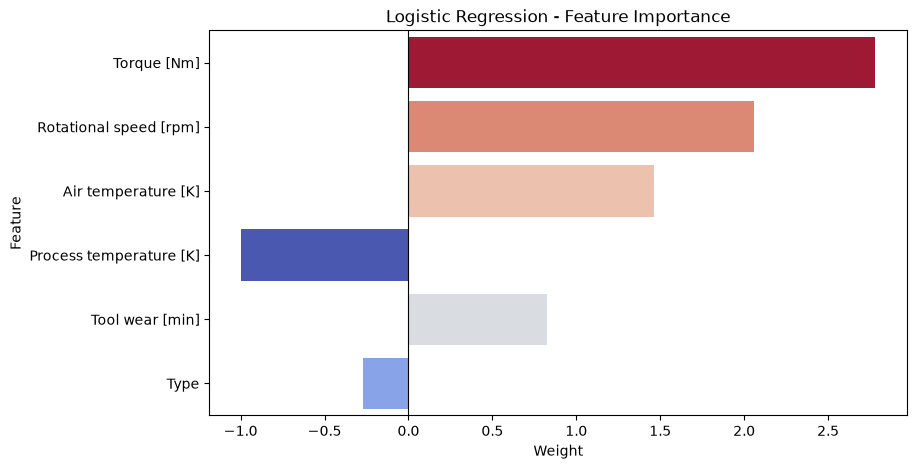

In [42]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=lr_importance,
    x='Weight',
    y='Feature',
    hue='Weight',
    palette='coolwarm',
    legend=False
)

plt.title('Logistic Regression - Feature Importance')
plt.axvline(x=0, color='black', linewidth=0.8)
plt.show()

In [43]:
rf_importance = pd.DataFrame({
    'Feature': X_features.columns,
    'Importance': rf_clf.feature_importances_
})

rf_importance = rf_importance.sort_values(
    by='Importance',
    ascending=False
)

print(rf_importance)

                   Feature  Importance
4              Torque [Nm]    0.329870
3   Rotational speed [rpm]    0.224051
5          Tool wear [min]    0.168514
2  Process temperature [K]    0.127891
1      Air temperature [K]    0.121969
0                     Type    0.027704


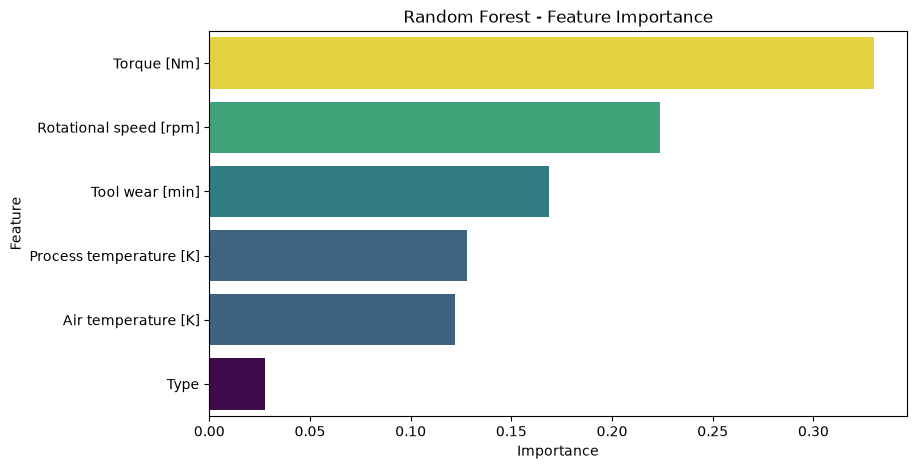

In [44]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=rf_importance,
    x='Importance',
    y='Feature',
    hue='Importance',
    palette='viridis',
    legend=False
)

plt.title('Random Forest - Feature Importance')
plt.show()

In [46]:
import eli5
from eli5.sklearn import PermutationImportance

In [47]:
# Model Agnostic

perm = PermutationImportance(
    lr_clf,
    random_state=42,
    n_iter=10
).fit(X_test, y_test)

eli5.show_weights(
    perm,
    feature_names=X_features.columns.tolist()
)

Weight,Feature
0.0780 ± 0.0035,Torque [Nm]
0.0549 ± 0.0056,Rotational speed [rpm]
0.0110 ± 0.0071,Air temperature [K]
0.0104 ± 0.0038,Process temperature [K]
0.0000 ± 0.0018,Tool wear [min]
-0.0010 ± 0.0010,Type


In [48]:
# Sample prediction

sample_data = X_test.iloc[[0]]

print("Actual Failure Type:", y_test.iloc[0])

print("Predicted Failure Type:", lr_clf.predict(sample_data)[0])

print("Prediction Probabilities:")
print(lr_clf.predict_proba(sample_data))

Actual Failure Type: 0
Predicted Failure Type: 0
Prediction Probabilities:
[[0.92906609 0.07093391]]


In [50]:
# Extract the trained Logistic Regression model

lr_model = lr_clf.named_steps['logisticregression']

# Extract the StandardScaler
scaler = lr_clf.named_steps['standardscaler']

In [51]:
# Transform sample data using the same scaler

scaled_sample = scaler.transform(sample_data)

In [52]:

# Explain a single prediction

eli5.show_prediction(
    lr_model,
    scaled_sample[0],
    feature_names=X_features.columns.tolist()
)


In [53]:
sample_data_2 = pd.DataFrame(
    [[2, 300.6, 310.6, 1448, 44.7, 55]],
    columns=X_features.columns
)

In [54]:
print("Predicted Failure Type:",
      lr_clf.predict(sample_data_2)[0])

print("Prediction Probabilities:",
      lr_clf.predict_proba(sample_data_2))

Predicted Failure Type: 0
Prediction Probabilities: [[0.99718157 0.00281843]]


In [56]:

# Explain a single prediction for sample_data_2

# Extract the trained Logistic Regression model
lr_model = lr_clf.named_steps['logisticregression']

# Extract the fitted scaler
scaler = lr_clf.named_steps['standardscaler']

# Scale the sample data
scaled_sample_2 = scaler.transform(sample_data_2)

# Explain the prediction
eli5.show_prediction(
    lr_model,
    scaled_sample_2[0],
    feature_names=X_features.columns.tolist()
)
